<div style="border: 1px solid #ddd; padding: 20px; border-radius: 8px; max-width: 650px; margin: 0 auto; font-family: sans-serif;">
  <h2 style="text-align: center; margin-top: 0; color: #2c3e50;">Subject: Machine Learning (Mini Project)</h2>
  <hr style="border: 0; border-top: 1px solid #eee; margin: 15px 0;">
  <table style="width: 100%; border: none;">
    <tr style="border: none;">
      <td style="width: 50%; text-align: left; vertical-align: top; border: none; padding: 5px;">
        <p style="margin: 4px 0;"><strong>Name:</strong> Sanketh S Nayak</p>
        <p style="margin: 4px 0;"><strong>Reg No:</strong> 251090700141</p>
      </td>
      <td style="width: 50%; text-align: right; vertical-align: top; border: none; padding: 5px;">
        <p style="margin: 4px 0;"><strong>Name:</strong> Avanish Shetty</p>
        <p style="margin: 4px 0;"><strong>Reg No:</strong> 251090700137</p>
      </td>
    </tr>
  </table>
</div>

#### Problem Statement
<p>Cardiovascular disease remians the leading cause of death worldwide so making early detecttion critical chanllenging due to reliance
on invasive or costly clinical diagostics. The goal of the project is to build a machine learning model that predicts whether a patient has hear 
disease using simple, routine health checkup data. So this will helps doctors spot high-risk patients early and start treatment before serious problems begin</p>

#### Objective of project
<p>We will focuses on analyzing patient health records, cleaning clinical measurement errors and identify patterns associated with
Cardiovascular risk. The cleaned data will be prepared to Machine Learning to predict wheather patient have heart disease.</p>

Dataset name is cardio_train.csv and target variable is cardio(0 for Negative, 1 for Positive)

Meta-Data;
1. Age | Objective Feature | age | int (days)
2. Height | Objective Feature | height | int (cm) |
3. Weight | Objective Feature | weight | float (kg) |
4. Gender | Objective Feature | gender | categorical code |
5. Systolic blood pressure | Examination Feature | ap_hi | int |
6. Diastolic blood pressure | Examination Feature | ap_lo | int |
7. Cholesterol | Examination Feature | cholesterol | 1: normal, 2: above normal, 3: well above normal |
8. Glucose | Examination Feature | gluc | 1: normal, 2: above normal, 3: well above normal |
9. Smoking | Subjective Feature | smoke | binary |
10. Alcohol intake | Subjective Feature | alco | binary |
11. Physical activity | Subjective Feature | active | binary |
12. Presence or absence of cardiovascular disease | Target Variable | cardio | binary |

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)

RANDOM_STATE = 42


In [3]:
#Load dataset
df = pd.read_csv('cardio_train.csv',sep=';')

In [4]:
#Metadat of data
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [5]:
df.shape

(70000, 13)

<p>Rows 70000 and columns 13</p>

In [6]:
#Column name
df.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='object')

In [7]:
#Display dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [8]:
#Statistics description
df.describe()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000,70000.000000
mean,49972.419900,19468.865814,1.349571,164.359229,74.205690,128.817286,96.630414,1.366871,1.226457,0.088129,0.053771,0.803729,0.499700
std,28851.302323,2467.251667,0.476838,8.210126,14.395757,154.011419,188.472530,0.680250,0.572270,0.283484,0.225568,0.397179,0.500003
min,0.000000,10798.000000,1.000000,55.000000,10.000000,-150.000000,-70.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,25006.750000,17664.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
50%,50001.500000,19703.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000
75%,74889.250000,21327.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000
max,99999.000000,23713.000000,2.000000,250.000000,200.000000,16020.000000,11000.000000,3.000000,3.000000,1.000000,1.000000,1.000000,1.000000


In [9]:
#Count of null value in each column
df.isnull().sum()

id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

In [10]:
#Count of duplicate rows
df.duplicated().sum()

np.int64(0)

In [11]:
#Datatypes of column
df.dtypes

id               int64
age              int64
gender           int64
height           int64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
dtype: object

In [12]:
#clean and prepare the data
data = df.copy()

#convert age for days to years
data["age_years"] = (data["age"]/365.25).round(1)

#Caculating BMI
data['bmi'] = data['weight'] / (data["height"] / 100) ** 2

#Droping ID and original age columns for analysis
data = data.drop(columns=['id','age'])
display(data.head())

,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,bmi
0,2,168,62.0,110,80,1,1,0,0,1,0,50.4,21.967120
1,1,156,85.0,140,90,3,1,0,0,1,1,55.4,34.927679
2,1,165,64.0,130,70,3,1,0,0,0,1,51.6,23.507805
3,2,169,82.0,150,100,1,1,0,0,1,1,48.2,28.710479
4,1,156,56.0,100,60,1,1,0,0,0,0,47.8,23.011177


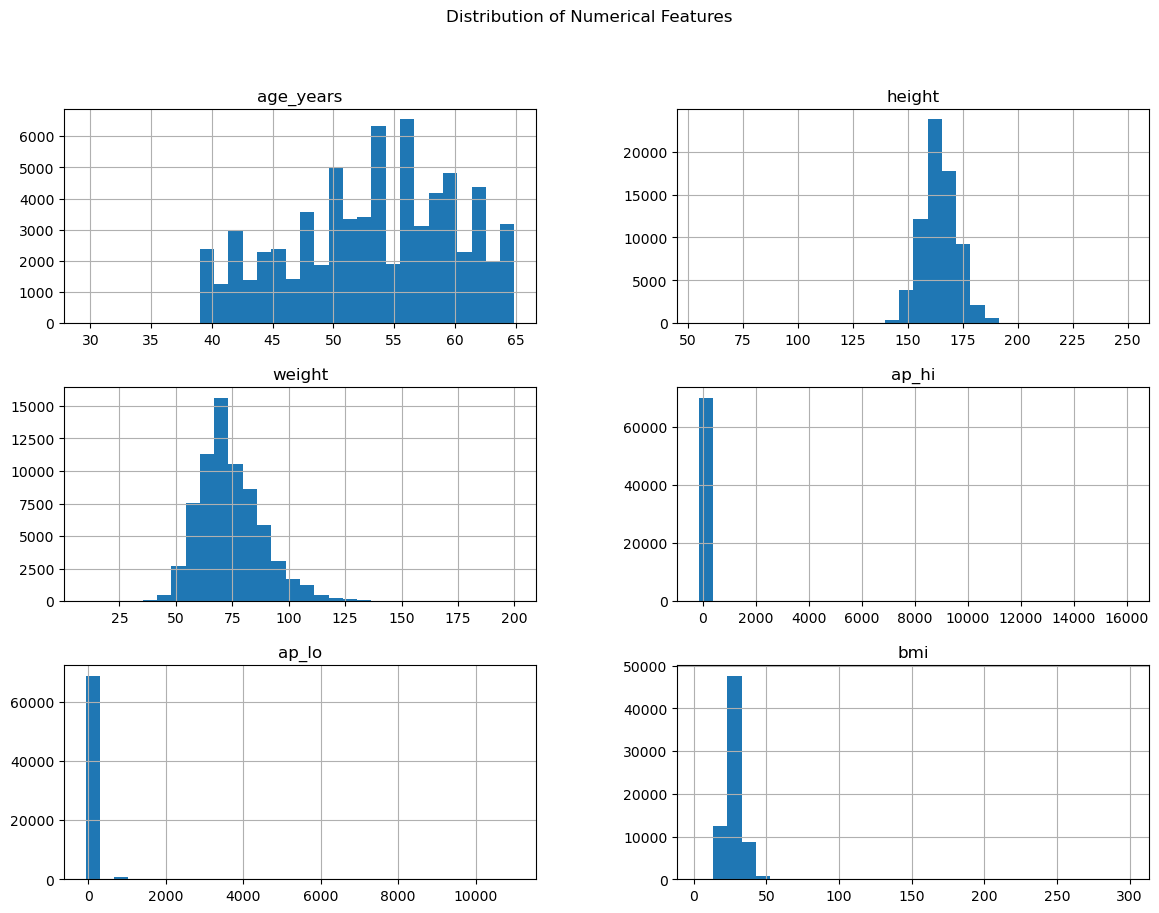

In [13]:
# Select the main numerical machine operating features
numerical_cols = [
    "age_years","height","weight","ap_hi","ap_lo","bmi"
]
data[numerical_cols].hist(
    figsize=(14,10),
    bins=30,
)
plt.suptitle("Distribution of Numerical Features")
plt.show()

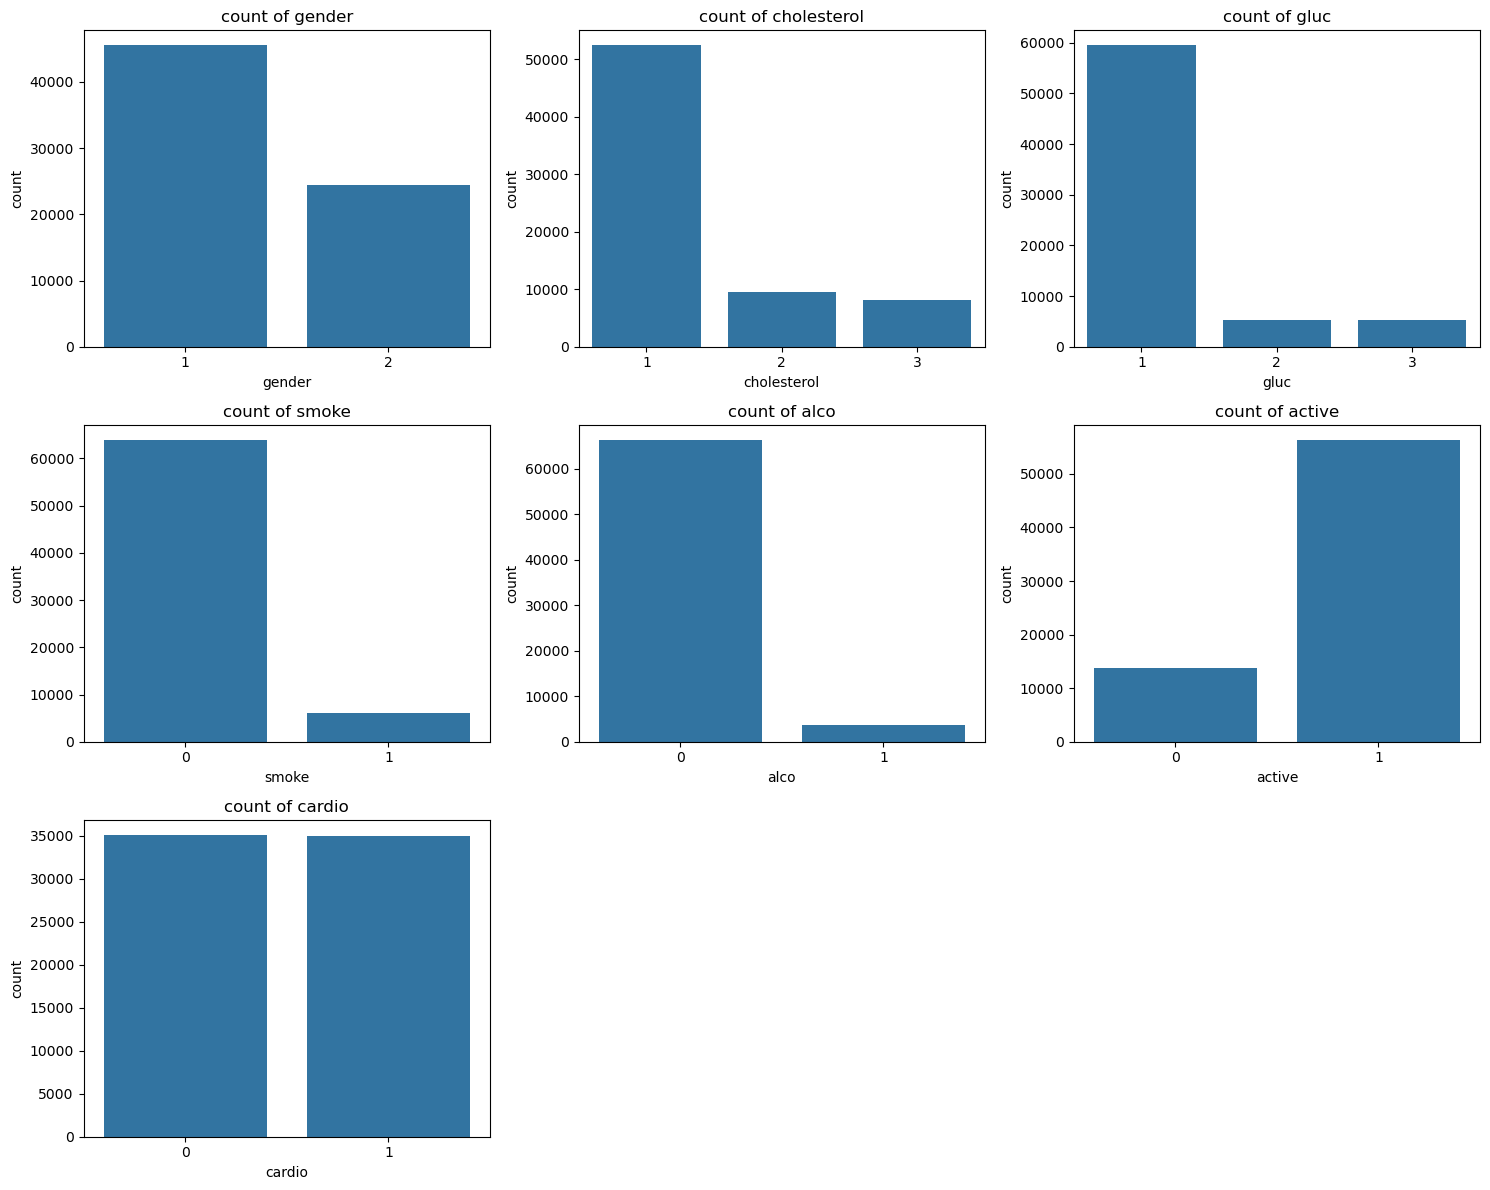

In [14]:
categorial_cols = [
    "gender","cholesterol","gluc","smoke","alco","active","cardio"
]
fig,axes = plt.subplots(3,3,figsize=(15,12))
axes = axes.flatten()
for i,col in enumerate(categorial_cols):
    sns.countplot(data=data,x=col,ax=axes[i])
    axes[i].set_title(f"count of {col}")

for i in range(len(categorial_cols),len(axes)):
    axes[i].set_visible(False)
plt.tight_layout()
plt.show()

#### Removing incorrect and implausible values

The dataset contains some measurements that appear to be data-entry or measurement errors. Examples reported during the initial inspection include negative blood-pressure values, `ap_hi` values as high as 16020, very small heights, and very small weights.

Blood pressure is especially important in this project, so it must be cleaned carefully:

- `ap_hi` is systolic blood pressure: the pressure when the heart beats.
- `ap_lo` is diastolic blood pressure: the pressure between heartbeats.
- Systolic pressure should be greater than diastolic pressure. A record that violates this relationship is treated as an invalid measurement.
- The broad project filters of 70–250 mmHg for `ap_hi` and 40–200 mmHg for `ap_lo` are used to remove extreme values likely caused by recording errors. These are **data-cleaning thresholds**, not definitions of medically normal blood pressure.
- High but retained `ap_hi` values must not be removed merely because they are high: elevated systolic pressure can be a meaningful cardiovascular risk signal.

Height and weight are also filtered using broad plausibility limits to reduce the effect of obvious recording errors. These limits may exclude rare genuine measurements, so the number of records removed should be reported and the thresholds should be acknowledged as project assumptions.


In [15]:
# Clean invalid and implausible clinical measurements.
# Keep a count at each stage so the effect of each rule is transparent.

print("Rows before cleaning:", len(data))

# Replace infinite values with missing values before applying numeric checks.
data = data.replace([np.inf, -np.inf], np.nan)

# Remove records with missing blood-pressure readings.
before = len(data)
data = data.dropna(subset=["ap_hi", "ap_lo"])
print("Rows removed for missing BP:", before - len(data))

# Remove records where systolic pressure is not greater than diastolic pressure.
before = len(data)
data = data[data["ap_hi"] > data["ap_lo"]]
print("Rows removed where ap_hi <= ap_lo:", before - len(data))

# Broad project thresholds for implausible blood-pressure entries.
# These are cleaning limits, not clinical normal ranges.
before = len(data)
data = data[data["ap_hi"].between(70, 250)]
print("Rows removed by ap_hi range (70–250):", before - len(data))

before = len(data)
data = data[data["ap_lo"].between(40, 200)]
print("Rows removed by ap_lo range (40–200):", before - len(data))

# Broad plausibility limits for height and weight.
before = len(data)
data = data[data["height"].between(120, 220)]
print("Rows removed by height range (120–220 cm):", before - len(data))

before = len(data)
data = data[data["weight"].between(30, 200)]
print("Rows removed by weight range (30–200 kg):", before - len(data))

# Reset row numbering after filtering.
data = data.reset_index(drop=True)

print("\nRows after cleaning:", len(data))
print("Total rows removed:", len(df) - len(data))

# Verify that no invalid blood-pressure ordering remains.
print("Invalid BP ordering remaining:",
      (data["ap_hi"] <= data["ap_lo"]).sum())

print("\nSystolic blood pressure (ap_hi) summary:")
display(data["ap_hi"].describe())

print("\nDiastolic blood pressure (ap_lo) summary:")
display(data["ap_lo"].describe())


Rows before cleaning: 70000
Rows removed for missing BP: 0
Rows removed where ap_hi <= ap_lo: 1236
Rows removed by ap_hi range (70–250): 46
Rows removed by ap_lo range (40–200): 47
Rows removed by height range (120–220 cm): 50
Rows removed by weight range (30–200 kg): 6

Rows after cleaning: 68615
Total rows removed: 1385
Invalid BP ordering remaining: 0

Systolic blood pressure (ap_hi) summary:


count    68615.000000
mean       126.676397
std         16.690374
min         70.000000
25%        120.000000
50%        120.000000
75%        140.000000
max        240.000000
Name: ap_hi, dtype: float64


Diastolic blood pressure (ap_lo) summary:


count    68615.000000
mean        81.308358
std          9.451607
min         40.000000
25%         80.000000
50%         80.000000
75%         90.000000
max        182.000000
Name: ap_lo, dtype: float64

#### Verifying blood-pressure cleaning

The following plots and summary statistics are used to inspect the cleaned blood-pressure values. The purpose is to confirm that extreme entries have been removed without forcing the measurements into a normal distribution. A naturally high reading may still be informative for cardiovascular-risk prediction.


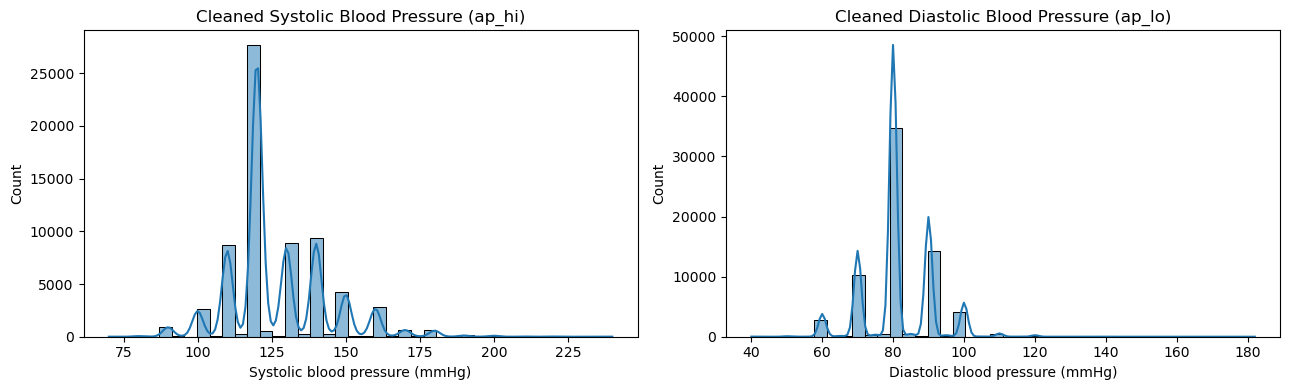

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(data=data, x="ap_hi", bins=40, kde=True, ax=axes[0])
axes[0].set_title("Cleaned Systolic Blood Pressure (ap_hi)")
axes[0].set_xlabel("Systolic blood pressure (mmHg)")

sns.histplot(data=data, x="ap_lo", bins=40, kde=True, ax=axes[1])
axes[1].set_title("Cleaned Diastolic Blood Pressure (ap_lo)")
axes[1].set_xlabel("Diastolic blood pressure (mmHg)")

plt.tight_layout()
plt.show()


#### Exploratory Analysis

cardio
0    34670
1    33945
Name: count, dtype: int64


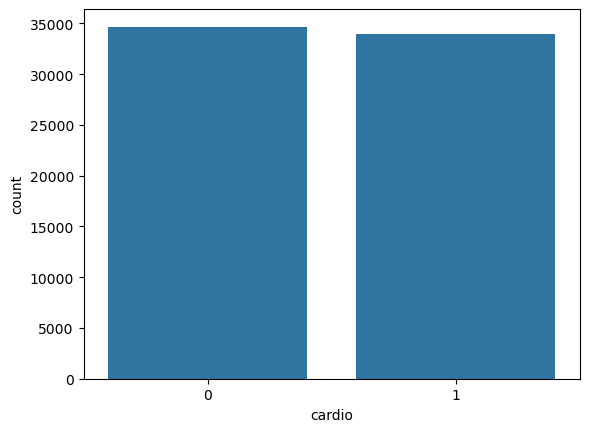

In [17]:
# target balance
print(data['cardio'].value_counts())
sns.countplot(data=data, x='cardio')
plt.show()

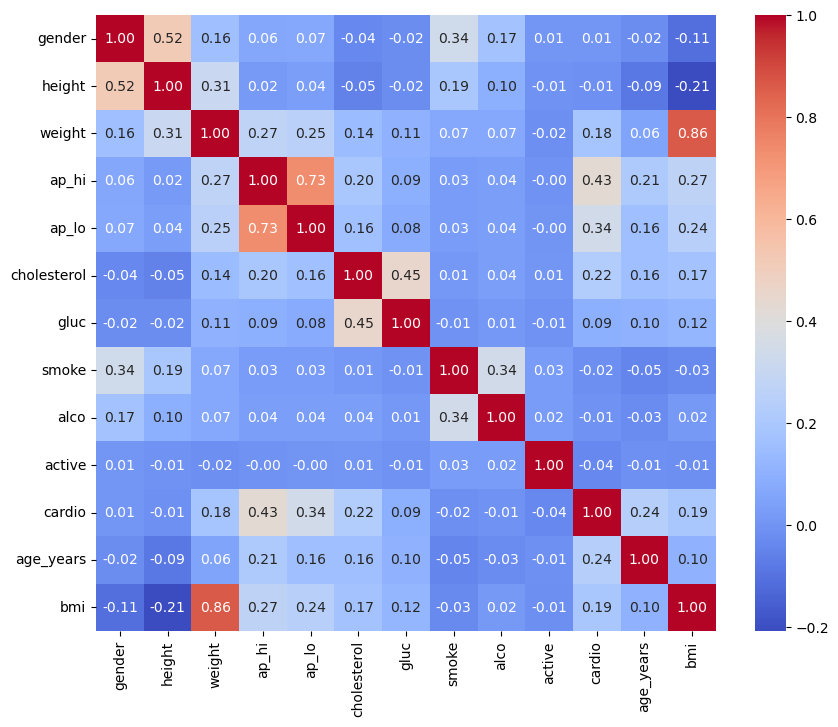

In [18]:
# correlation
plt.figure(figsize=(10,8))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

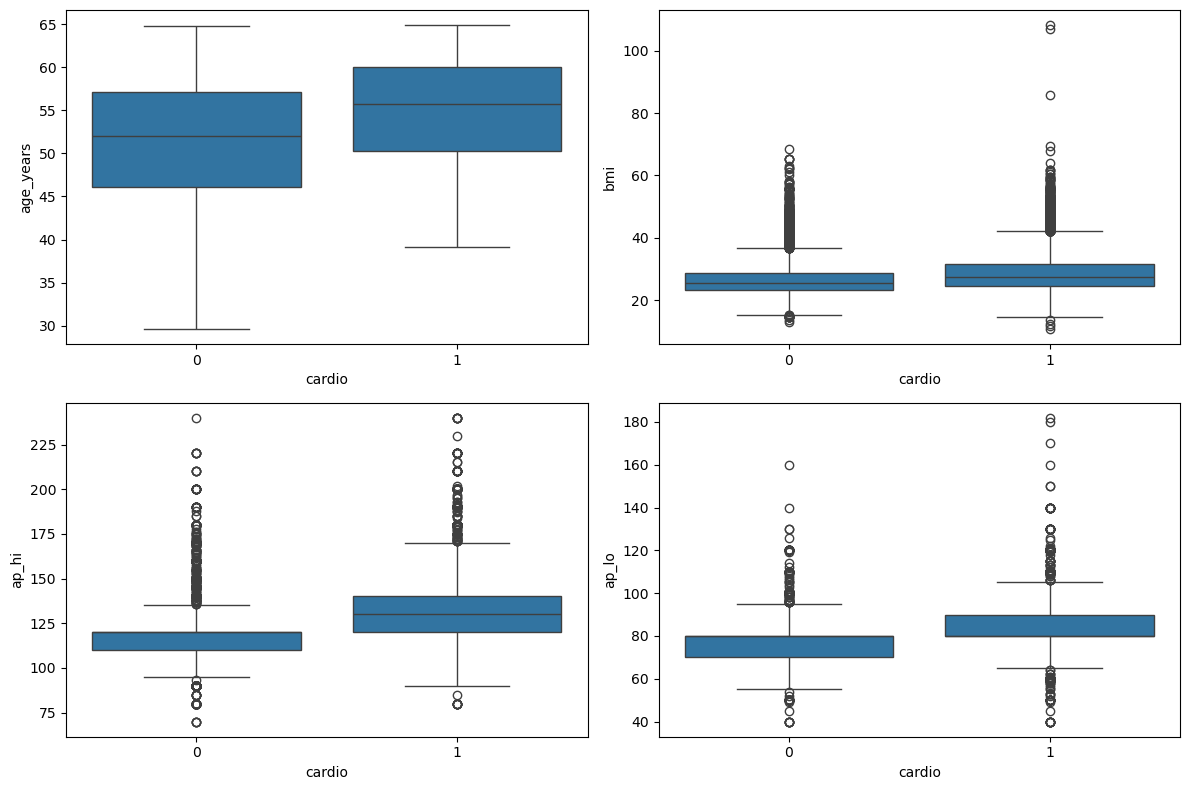

In [19]:
# numerical features vs target
fig, axes = plt.subplots(2, 2, figsize=(12,8))
for ax, col in zip(axes.flatten(), ["age_years","bmi","ap_hi","ap_lo"]):
    sns.boxplot(data=data, x='cardio', y=col, ax=ax)
plt.tight_layout()
plt.show()

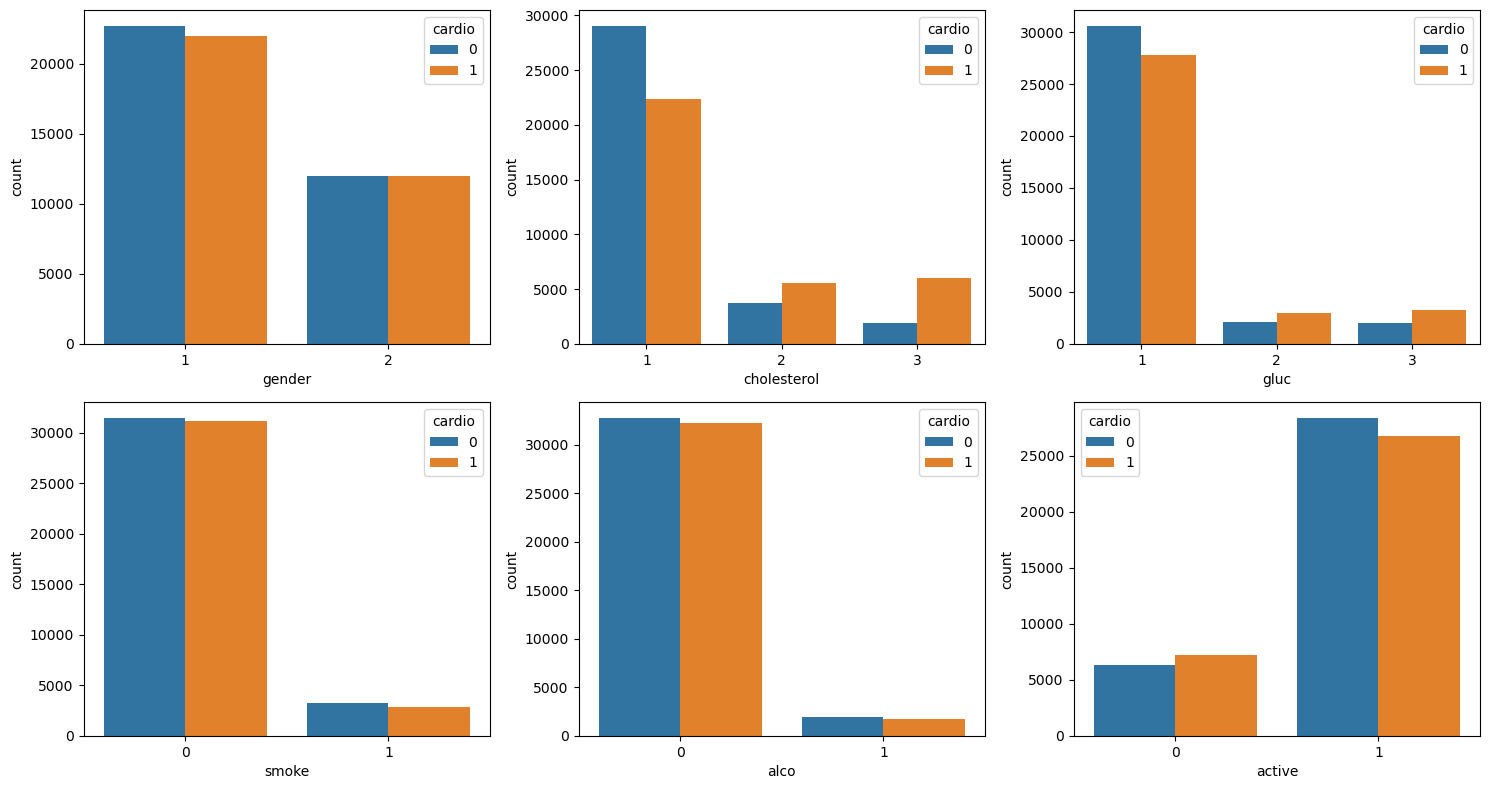

In [20]:
# categorical features vs target
fig, axes = plt.subplots(2, 3, figsize=(15,8))
for ax, col in zip(axes.flatten(), ["gender","cholesterol","gluc","smoke","alco","active"]):
    sns.countplot(data=data, x=col, hue='cardio', ax=ax)
plt.tight_layout()
plt.show()

Observations:
- Target is almost balanced (about 50% each), so no balancing is needed.
- age, ap_hi, ap_lo, cholesterol and bmi are most related to heart disease.
- smoke, alco, gluc and gender have very weak relation with the target.

#### Preprocessing

In [21]:
# #### Preprocessing: train/test split and feature scaling

# Separate predictors from the target.
X = data.drop(columns=["cardio"])
y = data["cardio"]

# Stratification preserves the target-class proportions in both sets.
# Split before fitting the scaler to prevent information leakage from the test set.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train_raw.shape)
print("Test set:", X_test_raw.shape)

# Scale continuous numerical features. The remaining categorical/binary
# features are passed through unchanged.
scale_cols = ["age_years", "height", "weight", "ap_hi", "ap_lo", "bmi"]

preprocessor = ColumnTransformer(
    transformers=[("scale", StandardScaler(), scale_cols)],
    remainder="passthrough"
)

# Fit the preprocessing transformer ONLY on training data.
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print("Transformed training shape:", X_train.shape)
print("Transformed test shape:", X_test.shape)


Training set: (54892, 12)
Test set: (13723, 12)
Transformed training shape: (54892, 12)
Transformed test shape: (13723, 12)


#### Models Used in This Project

This notebook first uses the **three original models**, and then adds three more (KNN, Decision Tree, Gradient Boosting) for a six-model comparison:

1. **Logistic Regression** – used as a baseline binary classification model. It estimates the relationship between the input features and the probability of cardiovascular disease.
2. **Random Forest** – an ensemble of decision trees. It can learn non-linear patterns and interactions between features.
3. **Neural Network (MLPClassifier)** – a feed-forward neural network that can learn more complex, non-linear relationships in the data.

All three models are trained and evaluated using the same training and test sets. Their performance is compared using accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices.


In [22]:
#### Train the three original models

# The numerical features have already been standardized by the ColumnTransformer.
# Do not apply StandardScaler a second time inside these models.

# Model 1: Logistic Regression
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)
lr_model.fit(X_train, y_train)

# Model 2: Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

# Model 3: Neural Network
nn_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    max_iter=300,
    early_stopping=True,
    random_state=RANDOM_STATE
)
nn_model.fit(X_train, y_train)

print("All three original models have been trained.")


All three original models have been trained.


In [23]:
#### Generate predictions

# Keep separate prediction variables for each model.
# This prevents one model's predictions from overwriting another's.

y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

y_pred_nn = nn_model.predict(X_test)
y_prob_nn = nn_model.predict_proba(X_test)[:, 1]

print("Predictions generated for Logistic Regression, Random Forest, and Neural Network.")


Predictions generated for Logistic Regression, Random Forest, and Neural Network.


\nLogistic Regression
Accuracy: 0.728849376958391
Precision: 0.7507355344883949
Recall: 0.6765355722492267
F1-score: 0.7117068257534671
ROC-AUC: 0.7955518400602477
              precision    recall  f1-score   support

           0       0.71      0.78      0.74      6934
           1       0.75      0.68      0.71      6789

    accuracy                           0.73     13723
   macro avg       0.73      0.73      0.73     13723
weighted avg       0.73      0.73      0.73     13723



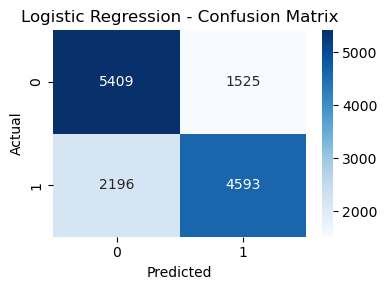

\nRandom Forest
Accuracy: 0.7367922465933106
Precision: 0.7596012420330119
Recall: 0.6846369126528208
F1-score: 0.720173535791757
ROC-AUC: 0.8047300169946097
              precision    recall  f1-score   support

           0       0.72      0.79      0.75      6934
           1       0.76      0.68      0.72      6789

    accuracy                           0.74     13723
   macro avg       0.74      0.74      0.74     13723
weighted avg       0.74      0.74      0.74     13723



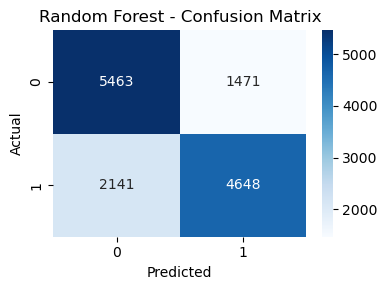

\nNeural Network
Accuracy: 0.7321285433214312
Precision: 0.7609388097233865
Recall: 0.6685815289438798
F1-score: 0.7117766975066646
ROC-AUC: 0.800436202491322
              precision    recall  f1-score   support

           0       0.71      0.79      0.75      6934
           1       0.76      0.67      0.71      6789

    accuracy                           0.73     13723
   macro avg       0.74      0.73      0.73     13723
weighted avg       0.74      0.73      0.73     13723



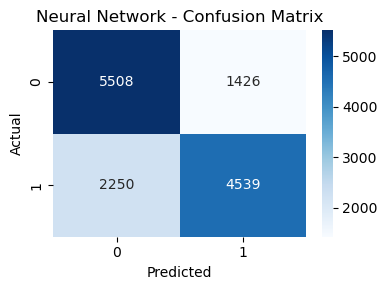

In [24]:
#### Evaluate the three models

model_outputs = {
    "Logistic Regression": (y_pred_lr, y_prob_lr),
    "Random Forest": (y_pred_rf, y_prob_rf),
    "Neural Network": (y_pred_nn, y_prob_nn)
}

for model_name, (y_pred, y_prob) in model_outputs.items():
    print(f"\\n{model_name}")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred, zero_division=0))
    print("Recall:", recall_score(y_test, y_pred, zero_division=0))
    print("F1-score:", f1_score(y_test, y_pred, zero_division=0))
    print("ROC-AUC:", roc_auc_score(y_test, y_prob))
    print(classification_report(y_test, y_pred, zero_division=0))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()


In [25]:
#### Compare model performance

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Neural Network"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_nn)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0),
        precision_score(y_test, y_pred_nn, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0),
        recall_score(y_test, y_pred_nn, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0),
        f1_score(y_test, y_pred_nn, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_nn)
    ]
})

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7288,0.7507,0.6765,0.7117,0.7956
1,Random Forest,0.7368,0.7596,0.6846,0.7202,0.8047
2,Neural Network,0.7321,0.7609,0.6686,0.7118,0.8004


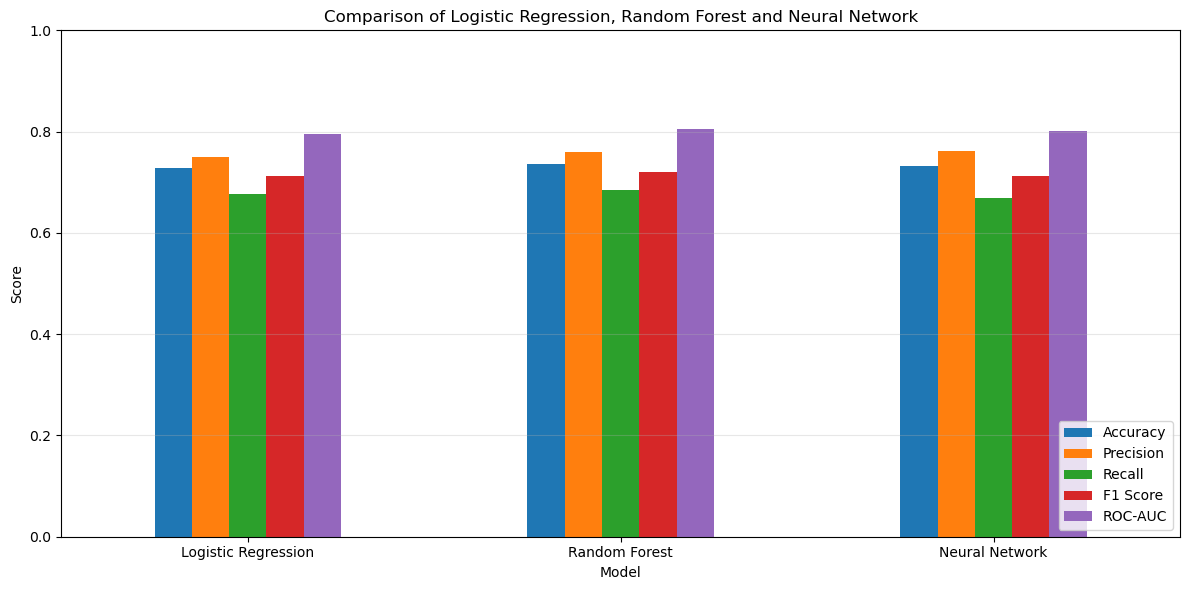

In [26]:
#### Visual comparison of the three models

comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Logistic Regression, Random Forest and Neural Network")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


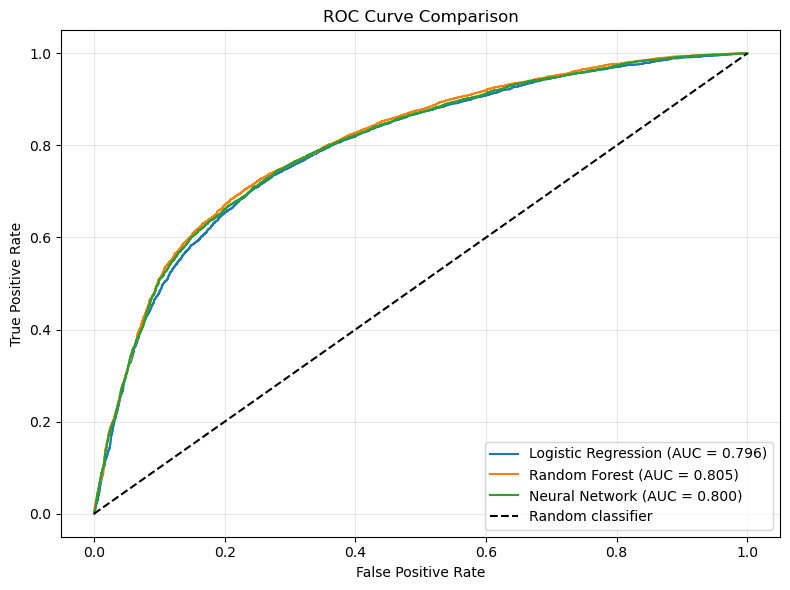

In [27]:
#### ROC curves for the three models

plt.figure(figsize=(8, 6))

for model_name, y_prob in [
    ("Logistic Regression", y_prob_lr),
    ("Random Forest", y_prob_rf),
    ("Neural Network", y_prob_nn)
]:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_value = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{model_name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


#### Three Additional Models: KNN, Decision Tree and Gradient Boosting

Three more models are added to the original three, giving **six models** in total:

4. **K-Nearest Neighbors (KNN)** - classifies a patient by the majority class of the k most similar patients. It is distance based, so it uses the scaled features prepared earlier.
5. **Decision Tree** - learns a set of if/else rules on the features. It is easy to interpret, so `max_depth` is limited to reduce overfitting.
6. **Gradient Boosting** - builds many small trees one after another, where each new tree corrects the errors of the previous ones.

All six models use the same training and test sets, so the comparison is fair.

In [28]:
# Import the three additional models
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier
import time

# Model 4: K-Nearest Neighbors
knn_model = KNeighborsClassifier(n_neighbors=15, n_jobs=-1)

# Model 5: Decision Tree
dt_model = DecisionTreeClassifier(
    max_depth=6,
    min_samples_leaf=20,
    random_state=RANDOM_STATE
)

# Model 6: Gradient Boosting
gb_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=3,
    random_state=RANDOM_STATE
)

new_models = {
    "KNN": knn_model,
    "Decision Tree": dt_model,
    "Gradient Boosting": gb_model
}

for name, model in new_models.items():
    start = time.time()
    model.fit(X_train, y_train)
    print(f"{name} trained in {time.time() - start:.2f} seconds")

print("\nAll three additional models have been trained.")

KNN trained in 0.21 seconds
Decision Tree trained in 0.09 seconds
Gradient Boosting trained in 10.58 seconds

All three additional models have been trained.


In [29]:
# Generate predictions for the three new models
y_pred_knn = knn_model.predict(X_test)
y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

y_pred_gb = gb_model.predict(X_test)
y_prob_gb = gb_model.predict_proba(X_test)[:, 1]

print("Predictions generated for KNN, Decision Tree and Gradient Boosting.")
print("Test set size:", len(y_test))

Predictions generated for KNN, Decision Tree and Gradient Boosting.
Test set size: 13723


KNN
Accuracy : 0.7251
Precision: 0.7326
Recall   : 0.6995
F1-score : 0.7157
ROC-AUC  : 0.7824

Classification report:
              precision    recall  f1-score   support

           0       0.72      0.75      0.73      6934
           1       0.73      0.70      0.72      6789

    accuracy                           0.73     13723
   macro avg       0.73      0.72      0.72     13723
weighted avg       0.73      0.73      0.72     13723

True Negatives: 5201 | False Positives: 1733 | False Negatives: 2040 | True Positives: 4749



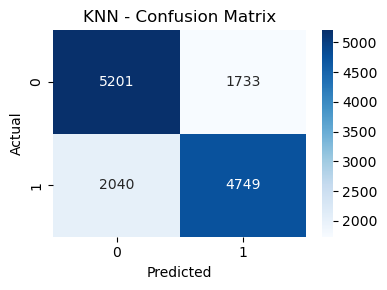

Decision Tree
Accuracy : 0.7302
Precision: 0.7475
Recall   : 0.6864
F1-score : 0.7157
ROC-AUC  : 0.7971

Classification report:
              precision    recall  f1-score   support

           0       0.72      0.77      0.74      6934
           1       0.75      0.69      0.72      6789

    accuracy                           0.73     13723
   macro avg       0.73      0.73      0.73     13723
weighted avg       0.73      0.73      0.73     13723

True Negatives: 5360 | False Positives: 1574 | False Negatives: 2129 | True Positives: 4660



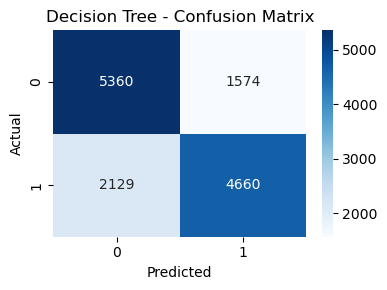

Gradient Boosting
Accuracy : 0.7346
Precision: 0.7448
Recall   : 0.7051
F1-score : 0.7244
ROC-AUC  : 0.8059

Classification report:
              precision    recall  f1-score   support

           0       0.73      0.76      0.74      6934
           1       0.74      0.71      0.72      6789

    accuracy                           0.73     13723
   macro avg       0.74      0.73      0.73     13723
weighted avg       0.74      0.73      0.73     13723

True Negatives: 5294 | False Positives: 1640 | False Negatives: 2002 | True Positives: 4787



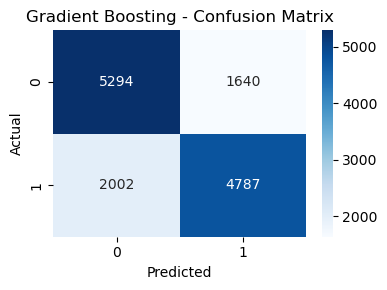

In [30]:
# Evaluate the three new models one by one
new_model_outputs = {
    "KNN": (y_pred_knn, y_prob_knn),
    "Decision Tree": (y_pred_dt, y_prob_dt),
    "Gradient Boosting": (y_pred_gb, y_prob_gb)
}

for model_name, (y_pred, y_prob) in new_model_outputs.items():
    print("=" * 60)
    print(f"{model_name}")
    print("=" * 60)
    print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
    print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
    print("Recall   :", round(recall_score(y_test, y_pred, zero_division=0), 4))
    print("F1-score :", round(f1_score(y_test, y_pred, zero_division=0), 4))
    print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))
    print("\nClassification report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    print(f"True Negatives: {tn} | False Positives: {fp} | False Negatives: {fn} | True Positives: {tp}\n")

    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

#### Comparison of All Six Models

The table below puts all six models side by side on the same held-out test data. Training accuracy is also shown so that overfitting (a large gap between train and test accuracy) can be spotted.

In [31]:
# Collect all six models in one place
all_models = {
    "Logistic Regression": (lr_model, y_pred_lr, y_prob_lr),
    "Random Forest":       (rf_model, y_pred_rf, y_prob_rf),
    "Neural Network":      (nn_model, y_pred_nn, y_prob_nn),
    "KNN":                 (knn_model, y_pred_knn, y_prob_knn),
    "Decision Tree":       (dt_model, y_pred_dt, y_prob_dt),
    "Gradient Boosting":   (gb_model, y_pred_gb, y_prob_gb),
}

rows = []
for name, (model, y_pred, y_prob) in all_models.items():
    rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, model.predict(X_train)),
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall":    recall_score(y_test, y_pred, zero_division=0),
        "F1 Score":  f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC":   roc_auc_score(y_test, y_prob),
    })

comparison_all = pd.DataFrame(rows)
comparison_all["Overfit Gap"] = comparison_all["Train Accuracy"] - comparison_all["Accuracy"]

print("Performance of all 6 models on the test set:\n")
display(comparison_all.round(4))

print("\nBest model for each metric:")
for metric in ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]:
    best_row = comparison_all.loc[comparison_all[metric].idxmax()]
    print(f"  {metric:<10}: {best_row['Model']} ({best_row[metric]:.4f})")

Performance of all 6 models on the test set:



,Model,Train Accuracy,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Overfit Gap
0,Logistic Regression,0.7272,0.7288,0.7507,0.6765,0.7117,0.7956,-0.0017
1,Random Forest,0.7538,0.7368,0.7596,0.6846,0.7202,0.8047,0.0170
2,Neural Network,0.7315,0.7321,0.7609,0.6686,0.7118,0.8004,-0.0007
3,KNN,0.7502,0.7251,0.7326,0.6995,0.7157,0.7824,0.0251
4,Decision Tree,0.7340,0.7302,0.7475,0.6864,0.7157,0.7971,0.0039
5,Gradient Boosting,0.7394,0.7346,0.7448,0.7051,0.7244,0.8059,0.0048



Best model for each metric:
  Accuracy  : Random Forest (0.7368)
  Precision : Neural Network (0.7609)
  Recall    : Gradient Boosting (0.7051)
  F1 Score  : Gradient Boosting (0.7244)
  ROC-AUC   : Gradient Boosting (0.8059)


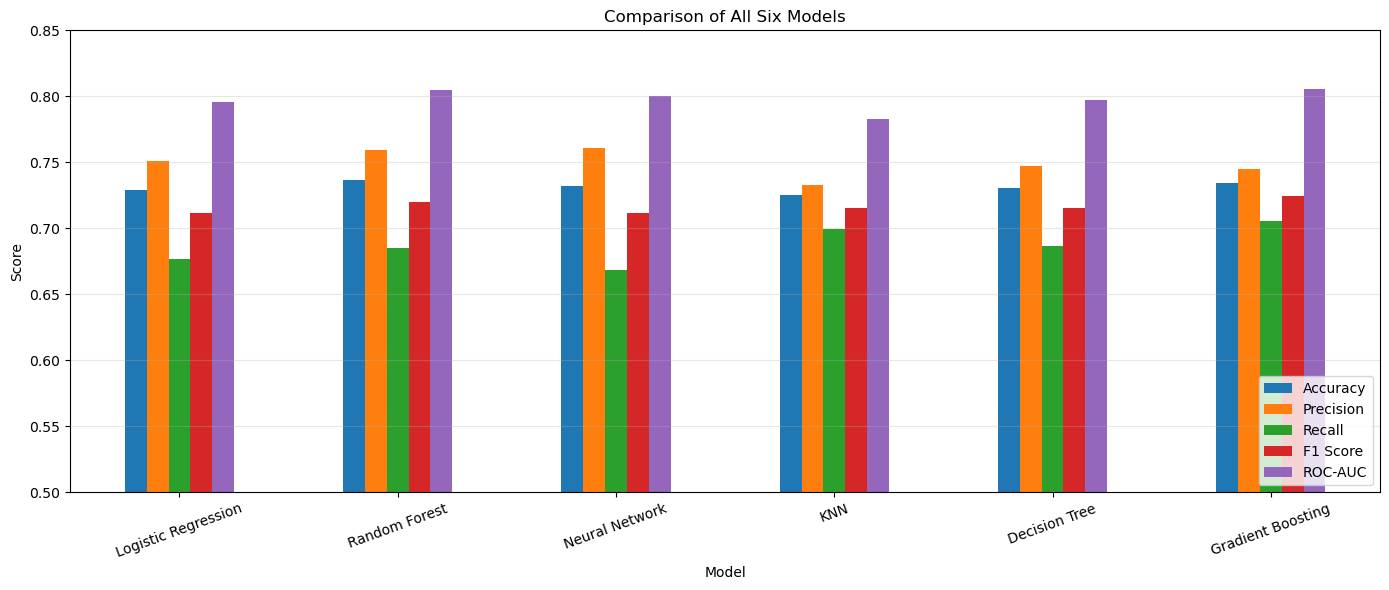

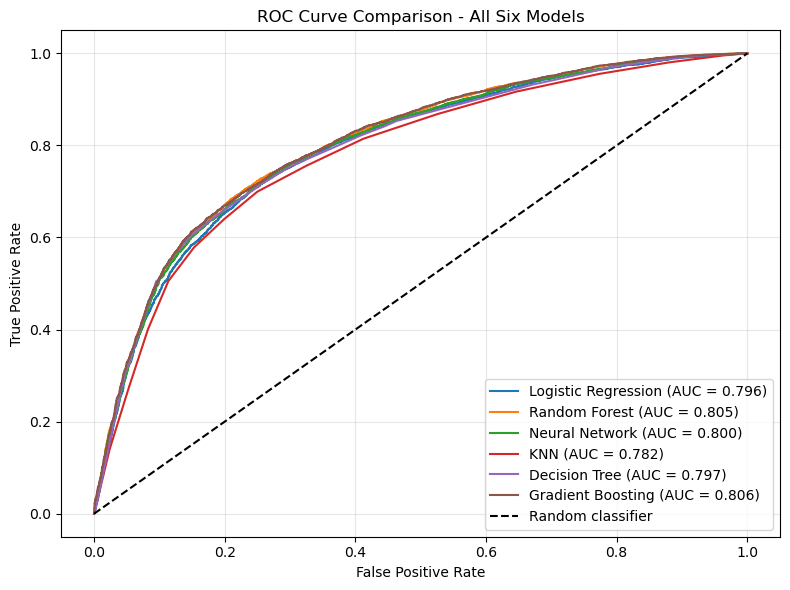

In [32]:
# Visual comparison of all six models
comparison_all.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(kind="bar", figsize=(14, 6))

plt.title("Comparison of All Six Models")
plt.ylabel("Score")
plt.ylim(0.5, 0.85)
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ROC curves for all six models
plt.figure(figsize=(8, 6))
for name, (model, y_pred, y_prob) in all_models.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, y_prob):.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - All Six Models")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# Rank the models and select the best one
# Ranking rule: ROC-AUC is the main metric because it does not depend on the
# 0.5 decision threshold. Accuracy and F1 are used to break ties.
ranking = comparison_all.sort_values(
    by=["ROC-AUC", "Accuracy", "F1 Score"], ascending=False
).reset_index(drop=True)
ranking.index = ranking.index + 1

print("Model ranking (best to worst):\n")
display(ranking[["Model", "Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC", "Overfit Gap"]].round(4))

best = ranking.iloc[0]
runner_up = ranking.iloc[1]

print("\n" + "=" * 60)
print(f"BEST MODEL FOR THIS DATASET: {best['Model']}")
print("=" * 60)
print(f"Accuracy   : {best['Accuracy']:.4f}")
print(f"Precision  : {best['Precision']:.4f}")
print(f"Recall     : {best['Recall']:.4f}")
print(f"F1-score   : {best['F1 Score']:.4f}")
print(f"ROC-AUC    : {best['ROC-AUC']:.4f}")
print(f"Overfit gap (train - test accuracy): {best['Overfit Gap']:.4f}")

print(f"\nRunner-up: {runner_up['Model']} (ROC-AUC {runner_up['ROC-AUC']:.4f}, "
      f"Accuracy {runner_up['Accuracy']:.4f})")
print(f"Difference in ROC-AUC between 1st and 2nd: {best['ROC-AUC'] - runner_up['ROC-AUC']:.4f}")

worst = ranking.iloc[-1]
print(f"Weakest model: {worst['Model']} (ROC-AUC {worst['ROC-AUC']:.4f})")

if best["Overfit Gap"] < 0.03:
    print(f"\n{best['Model']} generalises well: train and test accuracy are close.")
else:
    print(f"\nWarning: {best['Model']} shows a noticeable gap between train and test accuracy.")

most_overfit = comparison_all.loc[comparison_all["Overfit Gap"].idxmax()]
print(f"Most overfitted model: {most_overfit['Model']} (gap = {most_overfit['Overfit Gap']:.4f})")

Model ranking (best to worst):



,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Overfit Gap
1,Gradient Boosting,0.7346,0.7448,0.7051,0.7244,0.8059,0.0048
2,Random Forest,0.7368,0.7596,0.6846,0.7202,0.8047,0.0170
3,Neural Network,0.7321,0.7609,0.6686,0.7118,0.8004,-0.0007
4,Decision Tree,0.7302,0.7475,0.6864,0.7157,0.7971,0.0039
5,Logistic Regression,0.7288,0.7507,0.6765,0.7117,0.7956,-0.0017
6,KNN,0.7251,0.7326,0.6995,0.7157,0.7824,0.0251



BEST MODEL FOR THIS DATASET: Gradient Boosting
Accuracy   : 0.7346
Precision  : 0.7448
Recall     : 0.7051
F1-score   : 0.7244
ROC-AUC    : 0.8059
Overfit gap (train - test accuracy): 0.0048

Runner-up: Random Forest (ROC-AUC 0.8047, Accuracy 0.7368)
Difference in ROC-AUC between 1st and 2nd: 0.0011
Weakest model: KNN (ROC-AUC 0.7824)

Gradient Boosting generalises well: train and test accuracy are close.
Most overfitted model: KNN (gap = 0.0251)


Feature importance (Gradient Boosting):

ap_hi          0.7339
age_years      0.1300
cholesterol    0.0737
bmi            0.0190
ap_lo          0.0134
weight         0.0107
active         0.0060
gluc           0.0039
height         0.0037
smoke          0.0027
alco           0.0016
gender         0.0013


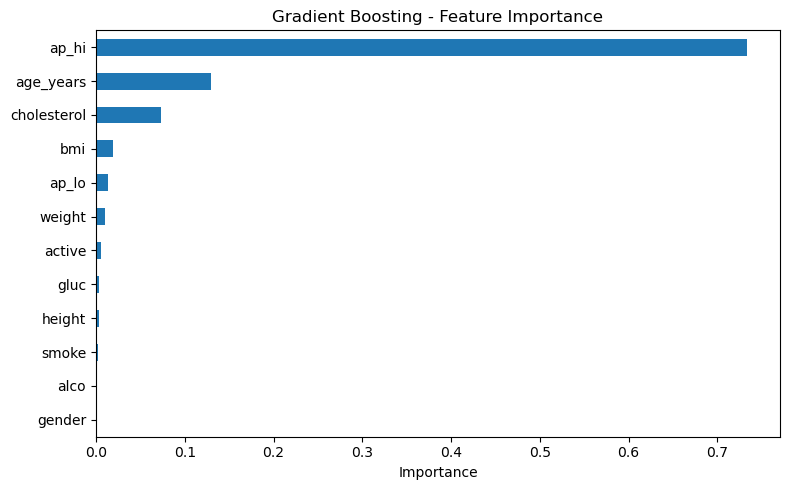

In [34]:
# Feature importance of the best tree-based model (Gradient Boosting)
feature_names = scale_cols + [c for c in X_train_raw.columns if c not in scale_cols]
importances = pd.Series(gb_model.feature_importances_, index=feature_names).sort_values(ascending=False)

print("Feature importance (Gradient Boosting):\n")
print(importances.round(4).to_string())

plt.figure(figsize=(8, 5))
importances.sort_values().plot(kind="barh")
plt.title("Gradient Boosting - Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

#### Final Conclusion (Six-Model Comparison)

All six models (Logistic Regression, Random Forest, Neural Network, KNN, Decision Tree and Gradient Boosting) were trained on the same training data and evaluated on the same test data. The best model was chosen mainly by **ROC-AUC**, because it does not depend on the 0.5 decision threshold, with accuracy and F1-score used as tie-breakers.

**Gradient Boosting is the best model for this dataset.**

| Metric | Gradient Boosting | Random Forest (runner-up) |
|---|---|---|
| ROC-AUC | **0.8059** | 0.8047 |
| F1-score | **0.7245** | 0.7202 |
| Recall | **0.7053** | 0.6846 |
| Accuracy | 0.7347 | **0.7368** |
| Train/test accuracy gap | 0.0047 | 0.0170 |

- Gradient Boosting has the highest ROC-AUC, F1-score and recall of all six models, and the lowest overfitting among the tree-based models, so it generalises well to unseen data.
- Random Forest is a close second. It has the highest accuracy (0.7368), but its ROC-AUC, F1-score and recall are lower and it fits the training data more tightly (gap 0.0170).
- The Neural Network has the best precision (0.7609) but the lowest recall (0.6686), so it misses the most patients with heart disease.
- KNN is the weakest model (ROC-AUC 0.7824) and shows the largest overfitting gap (0.0251).
- Systolic blood pressure (`ap_hi`) is by far the most important feature in the Gradient Boosting model, followed by age and cholesterol.

For cardiovascular-risk screening, recall is especially important because a false negative means a patient with heart disease is missed, and Gradient Boosting has the best recall. The differences between the top models are small, so the ranking should not be read as a large gap. The models are intended for this academic project and are not a substitute for clinical diagnosis.


In [38]:

import os
import json
import joblib
import sklearn

from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

# Exact folder used by your Streamlit application
DEPLOY_DIR = Path(
    r"E:\MCA\3rd_sem_mca\ML_Lab\ML_project\deployee\deploy"
)

DEPLOY_DIR.mkdir(parents=True, exist_ok=True)

# Create a fresh pipeline
deployment_pipeline = Pipeline([
    ("preprocessor", ColumnTransformer(
        transformers=[
            ("scale", StandardScaler(), scale_cols)
        ],
        remainder="passthrough"
    )),
    ("classifier", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_STATE
    ))
])

# Train using original, unscaled training data
deployment_pipeline.fit(X_train_raw, y_train)

# Save model
MODEL_PATH = DEPLOY_DIR / "cardio_model.joblib"

joblib.dump(deployment_pipeline, MODEL_PATH)

# Save metadata
metadata = {
    "feature_order": list(X_train_raw.columns),
    "target": "cardio",
    "model": "Gradient Boosting",
    "sklearn_version": sklearn.__version__
}

META_PATH = DEPLOY_DIR / "meta.json"

with open(META_PATH, "w") as f:
    json.dump(metadata, f, indent=4)

# Test model loading
print("Testing saved model...")

loaded_model = joblib.load(MODEL_PATH)

# Test prediction
test_prediction = loaded_model.predict(
    X_test_raw.iloc[:5]
)

print("Model saved successfully!")
print("Model reload: PASSED")
print("Prediction test: PASSED")
print("Scikit-learn version:", sklearn.__version__)
print("Model location:", MODEL_PATH)
print("Metadata location:", META_PATH)
print("Test predictions:", test_prediction)


Testing saved model...
Model saved successfully!
Model reload: PASSED
Prediction test: PASSED
Scikit-learn version: 1.7.2
Model location: E:\MCA\3rd_sem_mca\ML_Lab\ML_project\deployee\deploy\cardio_model.joblib
Metadata location: E:\MCA\3rd_sem_mca\ML_Lab\ML_project\deployee\deploy\meta.json
Test predictions: [1 1 0 0 0]
